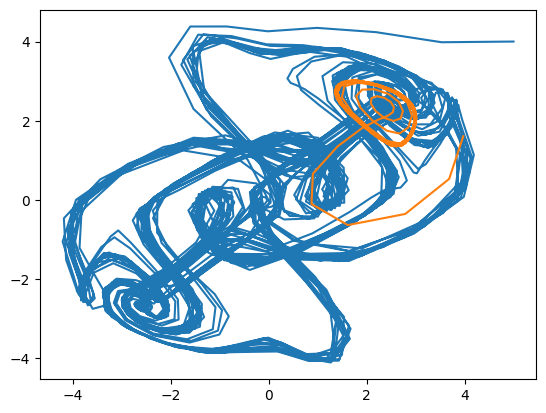

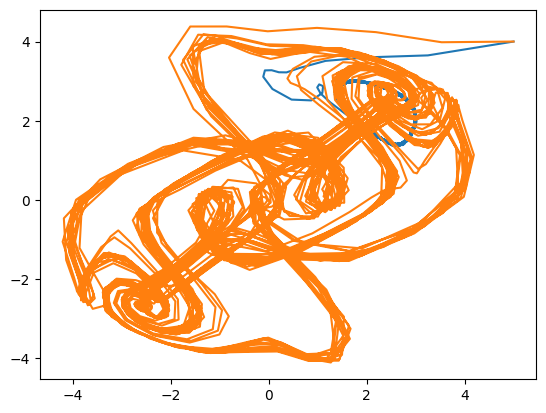

In [1]:
# Generate the data
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt

def rhs(_, y, b):
    return [
        np.sin(y[1]) - (b * y[0]),
        np.sin(y[2]) - (b * y[1]),
        np.sin(y[0]) - (b * y[2])
    ]

def single_b(b, T=10000, init=[5, 4, 3]):
    sol = solve_ivp(
		rhs, (0, T), init, args=(b,), t_eval=range(T)
	)
    return sol.y

def overlapping_b(b1, b2, T=10000):
    initial_vals = [5, 4, 3]
    hist = []
    bs = [b1, b2]
    
    for i in range(T//2000):
        hist.append(single_b(bs[i%2], T=2000, init=initial_vals))
        initial_vals = hist[-1][:, -1]

    return np.concatenate(hist, axis=1)

multi_t = overlapping_b(0.18, 0.29, T=20000)
plt.plot(multi_t[0, :2000], multi_t[1, :2000])
plt.plot(multi_t[0, 1999:4000], multi_t[1, 1999:4000])
plt.show()

periodic = single_b(0.29, T=10000, init=[5, 4, 3])
chaotic = single_b(0.18, T=10000, init=[5, 4, 3])

plt.plot(periodic[0, :2000], periodic[1, :2000])
plt.plot(chaotic[0, :2000], chaotic[1, :2000])
plt.show()

In [2]:
# ======================= Imports =======================
import numpy as np, pandas as pd, copy, time
from scipy.integrate import solve_ivp
from scipy.stats import wasserstein_distance
from spike_sharing import SpikingNetwork
import os

TWO_PI = 2 * np.pi

# ======================= Data =======================
def sim(b, n, init, transient=2000):
    sol = solve_ivp(rhs, (0, n + transient), init, args=(b,), t_eval=np.arange(n + transient),
                    rtol=1e-9, atol=1e-9)
    return sol.y[:, transient:]

def attractor_dist(a, b):
    if not np.all(np.isfinite(a)) or np.abs(a).max() > 10:
        return np.inf
    return np.mean([wasserstein_distance(a[d], b[d]) for d in range(3)])

def make_ref(n_ics, n_steps, seed):
    """Reference orbits; A is defined as the orbit of the first b=0.29 trajectory."""
    rng = np.random.default_rng(seed)
    out = {"chaotic": [sim(0.18, n_steps, rng.uniform(-4, 4, 3)) for _ in range(n_ics)],
           "periodic_A": [], "periodic_B": []}
    exemplar = None
    while min(len(out["periodic_A"]), len(out["periodic_B"])) < n_ics:
        traj = sim(0.29, n_steps, rng.uniform(-4, 4, 3))
        exemplar = traj if exemplar is None else exemplar
        k = "periodic_A" if attractor_dist(traj, exemplar) < 0.1 else "periodic_B"
        if len(out[k]) < n_ics:
            out[k].append(traj)
    return {k: np.concatenate(v, axis=1) for k, v in out.items()}

REF = make_ref(2, 5000, seed=300)

def ref_label(traj):
    return min(("periodic_A", "periodic_B"), key=lambda k: attractor_dist(traj, REF[k]))

def make_states(n_ics, n_steps, seed):
    """Test/validation trajectories, periodic ones labeled against REF so labels are consistent."""
    rng = np.random.default_rng(seed)
    out = {"chaotic": [sim(0.18, n_steps, rng.uniform(-4, 4, 3)) for _ in range(n_ics)],
           "periodic_A": [], "periodic_B": []}
    while min(len(out["periodic_A"]), len(out["periodic_B"])) < n_ics:
        traj = sim(0.29, n_steps, rng.uniform(-4, 4, 3))
        k = ref_label(traj)
        if len(out[k]) < n_ics:
            out[k].append(traj)
    return out

TRAIN = multi_t[:, :8000]                       # chaos / periodic / chaos / periodic, 2000 steps each
VAL   = make_states(2, 2500, seed=100)
TEST  = make_states(4, 2500, seed=200)

SELF = {k: attractor_dist(v[:, :v.shape[1] // 2], v[:, v.shape[1] // 2:]) for k, v in REF.items()}
print("self-distance:", {k: round(v, 3) for k, v in SELF.items()})
print("A vs B:", round(attractor_dist(REF["periodic_A"], REF["periodic_B"]), 3))
for i in (1, 3):
    seg = TRAIN[:, i * 2000 + 500:(i + 1) * 2000]
    print(f"train periodic segment {i}:", {k: round(attractor_dist(seg, r), 3) for k, r in REF.items()})

def classify(pred):
    d = {k: attractor_dist(pred, r) for k, r in REF.items()}
    best, second = sorted(d, key=d.get)[:2]
    ok = d[best] < 1.0 and d[best] < 0.5 * d[second]
    return (best if ok else "none"), d

def valid_time(pred, truth, thresh=0.4):
    n = min(pred.shape[1], truth.shape[1])
    err = np.linalg.norm(pred[:, :n] - truth[:, :n], axis=0) / np.sqrt(np.mean(np.sum(truth**2, axis=0)))
    bad = np.where(~np.isfinite(err) | (err > thresh))[0]
    return bad[0] if len(bad) else n

# ======================= Spiking model with readout phase =======================
class SpikingPsi(SpikingNetwork):
    """Link dynamics unchanged. Node modulation = 1 - (c/2)(1 + Im(rel_lp * e^{i psi_ref})),
    rel_lp = low-passed e^{i(theta_i - psi)}. psi_ref advances at Omega_ref while unfrozen (if sweep_train)."""
    def __init__(self, **kwargs):
        self.Omega_ref = kwargs.get("Omega_ref", 0.01)
        self.sweep_train = kwargs.get("sweep_train", True)
        self.log_every = kwargs.get("log_every", 10)
        self.log_mod = False
        self.mod_log, self.mod_log_t, self._step = [], [], 0
        super().__init__(**kwargs)

    def reset_link_bookkeeping(self, *args, **kwargs):
        super().reset_link_bookkeeping(*args, **kwargs)
        self.psi_ref = 0.0
        self.rel_lp = None

    def modulation(self):
        c = self.link_strength_change_ratio
        return 1 - (c / 2) * (1 + np.imag(self.rel_lp * np.exp(1j * self.psi_ref)))

    def advance_nodes(self, input_state, save_history=True):
        phase = self.link_phase
        valid = np.isfinite(phase)
        psi = np.angle(np.mean(np.exp(1j * phase[valid]))) if valid.any() else 0.0
        rel = np.zeros(phase.shape, dtype=complex)
        rel[valid] = np.exp(1j * (phase[valid] - psi))    # undefined phase -> 0 (midpoint modulation)
        if self.rel_lp is None:
            self.rel_lp = rel
        elif not self.frozen:
            self.rel_lp = self.rel_lp + (rel - self.rel_lp) / self.mod_tau
        m = self.modulation()
        W = self.node_adj_matrix.copy()
        W.data *= m                                       # same link ordering as the parent class
        self.node_states = self.leakage * self.node_states + (1 - self.leakage) * np.tanh(
            W.dot(self.node_states) + self.input_weights @ input_state + self.bias_nodes)
        if not self.frozen and self.sweep_train:
            self.psi_ref = (self.psi_ref + self.Omega_ref) % TWO_PI
        if self.log_mod and self._step % self.log_every == 0:
            self.mod_log.append(m.copy()); self.mod_log_t.append(self._step)
        self._step += 1
        if save_history:
            self.node_states_history.append(np.copy(self.node_states))
            self.training_data_history.append(np.copy(input_state))

def spk_settle(net, data, n_settle, offset):
    net.reset_initial_states(offset); net.reset_history()
    net.frozen, net.log_mod = False, False
    for t in range(n_settle):
        net.advance(data[:, t], save_history=False)
    return net

def spk_search_and_predict(warm_net, data, n_settle, W_out, n_auto, search=True, n_reentrain=50, smooth=20):
    net = copy.deepcopy(warm_net)
    net.output_weights = W_out
    net.frozen = True                                     # links and rel_lp held from here on
    t = n_settle
    if search:                                            # one full turn of psi_ref, open loop
        n_rot = int(np.ceil(TWO_PI / net.Omega_ref))
        psis, errs = [], []
        for _ in range(n_rot):
            net.psi_ref = (net.psi_ref + net.Omega_ref) % TWO_PI
            net.advance_nodes(data[:, t], save_history=False)
            psis.append(net.psi_ref)
            errs.append(np.sum((W_out @ net.node_states - data[:, t + 1])**2))
            t += 1
        e = np.convolve(errs, np.ones(smooth) / smooth, mode="same")
        net.psi_ref = psis[int(np.argmin(e))]
    for _ in range(n_reentrain):                          # nodes re-entrain to the chosen W_eff, open loop
        net.advance_nodes(data[:, t], save_history=False); t += 1
    m_frozen = net.modulation().copy()
    preds, out = [], W_out @ net.node_states              # out predicts data[:, t]
    for _ in range(n_auto):
        preds.append(out)
        net.advance_nodes(out, save_history=False)
        out = W_out @ net.node_states
    R = np.abs(np.nanmean(np.exp(1j * net.link_phase)))
    return np.asarray(preds).T, t, R, m_frozen

def nn_dist(m, M):
    return np.sqrt(np.min(np.mean((M - m)**2, axis=1)))

BASE = dict(input_dims=3, spectral_radius=0.6, input_weight=120e-2, average_degree_nodes=10,
            num_nodes=100, leakage=0, omega0=0.4, epsilon2=0.6, epsilon1=-0.15,
            link_coupling=1.4, coupling_I_max=10, subtract_dc=True, I_ref=39.96 + 15,
            mod_tau=60, Omega_ref=0.01)
ALPHAS = [1e-8, 1e-5, 1e-3, 1e-2, 1e-1, 1e0]
N_AUTO, DISCARD, WARM_TRAIN = 1200, 200, 200
ABLATIONS = [dict(name="c0_spkpath",  c=0.0, sweep_train=True,  search=True,  settle=500,  seeds=[0, 1]),
             dict(name="no_sweep",    c=0.6, sweep_train=False, search=False, settle=500,  seeds=[0, 1, 2, 3]),
             dict(name="no_search",   c=0.6, sweep_train=True,  search=False, settle=500,  seeds=[0, 1, 2, 3]),
             dict(name="long_settle", c=0.6, sweep_train=True,  search=True,  settle=1000, seeds=[0, 1, 2, 3])]

self-distance: {'chaotic': 0.058, 'periodic_A': 0.0, 'periodic_B': 0.0}
A vs B: 4.511
train periodic segment 1: {'chaotic': 2.437, 'periodic_A': 0.004, 'periodic_B': 4.511}
train periodic segment 3: {'chaotic': 2.242, 'periodic_A': 4.511, 'periodic_B': 0.004}


In [3]:
from itertools import combinations

def settle_record(net, data, n_settle, offset, r_window=200):
    """Reset + settle; return R averaged over the last r_window steps."""
    net.reset_initial_states(offset); net.reset_history()
    net.frozen, net.log_mod = False, False
    Rs = []
    for t in range(n_settle):
        net.advance(data[:, t], save_history=False)
        if t >= n_settle - r_window:
            Rs.append(np.abs(np.nanmean(np.exp(1j * net.link_phase))))
    return np.mean(Rs)

def context_vectors(params, n_ics=6, n_settle=1000, seed=500, model_seed=0):
    """One reservoir, n_ics fresh trajectories per state. Records the post-settle context."""
    sets = make_states(n_ics, n_settle, seed=seed)
    net = SpikingPsi(**params, model_seed=model_seed)
    c = net.link_strength_change_ratio
    rows, vecs = [], []
    for state, trajs in sets.items():
        for ic, data in enumerate(trajs):
            R = settle_record(net, data, n_settle, offset=1 + ic)
            z = net.rel_lp.copy()
            mag = np.abs(z)
            rows.append(dict(state=state, ic=ic, R=R, mag_mean=mag.mean(), mag_std=mag.std(),
                             frac_undef=np.mean(~np.isfinite(net.link_phase))))
            vecs.append(dict(state=state,
                             complex=z,                                    # full relative-phase info
                             mag=mag,                                      # locking strength only
                             mod0=1 - (c / 2) * (1 + np.imag(z))))         # current readout at psi_ref = 0
    return pd.DataFrame(rows), vecs

def separability(vecs, key):
    """RMS distance between context vectors: mean within-state, between-state, and per state pair."""
    S = [v["state"] for v in vecs]; X = [v[key] for v in vecs]
    d = lambda a, b: np.sqrt(np.mean(np.abs(a - b) ** 2))
    within, between, pair = [], [], {}
    for i, j in combinations(range(len(X)), 2):
        dij = d(X[i], X[j])
        (within if S[i] == S[j] else between).append(dij)
        pair.setdefault("|".join(sorted((S[i], S[j]))), []).append(dij)
    out = {k: np.mean(v) for k, v in pair.items()}
    out.update(within=np.mean(within), between=np.mean(between),
               ratio=np.mean(within) / np.mean(between))
    return out

In [4]:
class SpikingFreq(SpikingPsi):
    """Variant A. Drive sets each link's current (class I: drive -> frequency);
    diffusive coupling with constant attractive gain link_coupling*eps_A (no drive dependence, no repulsion)."""
    def __init__(self, **kwargs):
        self.g_freq = kwargs.get("g_freq", 10.0)
        self.eps_A = kwargs.get("eps_A", 0.3)
        self.I_floor = kwargs.get("I_floor", 39.96 + 1.0)        # keep every link above I_c
        super().__init__(**kwargs)

    def advance_links(self, save_history=True, freezing=False):
        if freezing:                                             # parent's free-run / hold logic unchanged
            return super().advance_links(save_history=save_history, freezing=freezing)
        node_drive = (self.incidence_T @ ((self.node_states + 1) / 2)) / self.incidence_norm
        I_ext = np.maximum(self.I_ref + self.g_freq * (node_drive - 0.5), self.I_floor)
        self.integrate_and_update(I_ext, self.link_coupling * self.eps_A)
        self.link_phase = self.measured_phase()
        if save_history:
            self.link_states_history.append(np.copy(self.link_states))
            self.link_phase_history.append(np.copy(self.link_phase))

In [5]:
def settle_record(net, data, n_settle, offset, r_window=200):
    net.reset_initial_states(offset); net.reset_history()
    net.frozen, net.log_mod = False, False
    Rs, rates = [], []
    for t in range(n_settle):
        net.advance(data[:, t], save_history=False)
        if t >= n_settle - r_window:
            Rs.append(np.abs(np.nanmean(np.exp(1j * net.link_phase))))
            rates.append(1.0 / net.last_isi)
    return np.mean(Rs), np.nan_to_num(np.nanmean(rates, axis=0))

def context_vectors(params, cls=SpikingPsi, n_ics=6, n_settle=1000, seed=500, model_seed=0):
    sets = make_states(n_ics, n_settle, seed=seed)
    net = cls(**params, model_seed=model_seed)
    c = net.link_strength_change_ratio
    rows, vecs = [], []
    for state, trajs in sets.items():
        for ic, data in enumerate(trajs):
            R, rate = settle_record(net, data, n_settle, offset=1 + ic)
            z = net.rel_lp.copy(); mag = np.abs(z)
            rows.append(dict(state=state, ic=ic, R=R, mag_mean=mag.mean(), mag_std=mag.std(),
                             frac_undef=np.mean(~np.isfinite(net.link_phase))))
            vecs.append(dict(state=state, complex=z, mag=mag, rate=rate,
                             mod0=1 - (c / 2) * (1 + np.imag(z))))
    return pd.DataFrame(rows), vecs

def periodic_score(vecs, key):
    s = separability(vecs, key)
    w = 0.5 * (s["periodic_A|periodic_A"] + s["periodic_B|periodic_B"])
    return w / s["periodic_A|periodic_B"]

In [6]:
P0 = dict(BASE, link_strength_change_ratio=0.6)
# CONFIGS = [("baseline", SpikingPsi, {}), ("A_ctrl_g0", SpikingFreq, dict(g_freq=0.0, eps_A=0.3))] +
# CONFIGS = [(f"A_g{g:g}_e{e:g}", SpikingFreq, dict(g_freq=g, eps_A=e)) for g in (7.5, 10, 12.5) for e in (0.3, 0.45, 0.6)]
# res = []
# for name, cls, change in CONFIGS:
#     st, vs = context_vectors(dict(P0, **change), cls=cls, n_ics=4)
#     g = st.groupby("state")[["R", "mag_mean", "frac_undef"]].mean()
#     row = dict(config=name, R_chaos=g.R["chaotic"], R_A=g.R["periodic_A"], R_B=g.R["periodic_B"],
#                mag_per=g.mag_mean[["periodic_A", "periodic_B"]].mean(), undef=g.frac_undef.max())
#     for key in ("complex", "mag", "rate"):
#         row[f"{key}_ratio"] = periodic_score(vs, key)
#     res.append(row)
#     print(name, "done", flush=True)
# print(pd.DataFrame(res).round(3).to_string(index=False))

In [15]:
# ===== Recall ablations: variant A vs c = 0 =====
import os

A_MAIN = dict(g_freq=10.0, eps_A=0.45)
ABLATIONS = [
    dict(name="A_fixpsi",       cls=SpikingFreq, extra=A_MAIN,                       c=0.6, sweep_train=False, search=False, settle=1000, seeds=[0, 1, 2, 3]),
    dict(name="A_g12.5_fixpsi", cls=SpikingFreq, extra=dict(g_freq=12.5, eps_A=0.6), c=0.6, sweep_train=False, search=False, settle=1000, seeds=[0, 1]),
]
OUT = "spk_freq_fixpsi.csv"
OUT = "spk_freq_ablations.csv"
SEG, EXCL = 2000, 3 * BASE["mod_tau"]

# rows = []
# for ab in ABLATIONS:
#     for seed in ab["seeds"]:
#         t0 = time.time()
#         net = ab["cls"](**BASE, **ab["extra"], link_strength_change_ratio=ab["c"],
#                         sweep_train=ab["sweep_train"], model_seed=seed)

#         # train, logging the modulation seen at each step (aligned with TRAIN indices)
#         net.mod_log, net.mod_log_t, net._step = [], [], 0
#         net.log_mod = True
#         net.train(TRAIN, warmup_time=WARM_TRAIN)
#         net.log_mod = False
#         M, Tm = np.asarray(net.mod_log), np.asarray(net.mod_log_t)
#         net.mod_log, net.mod_log_t = [], []                    # don't carry the log into deepcopies
#         keep = (Tm >= WARM_TRAIN) & ((Tm % SEG) >= EXCL)       # drop contexts still adapting after a switch
#         M, Tm = M[keep], Tm[keep]
#         periodic_seg = (Tm // SEG) % 2 == 1                    # TRAIN layout: chaos, periodic, chaos, periodic

#         W = {}
#         for a in ALPHAS:
#             net.regularization, net.lsqrs = a, False
#             net.compute_weights()
#             W[a] = np.copy(net.output_weights)

#         for split, sets in (("val", VAL), ("test", TEST)):
#             for state, trajs in sets.items():
#                 same = periodic_seg if state.startswith("periodic") else ~periodic_seg
#                 for ic, data in enumerate(trajs):
#                     warm = spk_settle(net, data, ab["settle"], offset=1 + ic)
#                     for a in ALPHAS:
#                         pred, ts, R, m_fz = spk_search_and_predict(warm, data, ab["settle"], W[a], N_AUTO,
#                                                                     search=ab["search"])
#                         label, d = classify(pred[:, DISCARD:])
#                         rows.append(dict(model=ab["name"], seed=seed, alpha=a, split=split, state=state, ic=ic,
#                                          pred_state=label, correct=(label == state), R_freeze=R,
#                                          d_same=nn_dist(m_fz, M[same]), d_other=nn_dist(m_fz, M[~same]),
#                                          vpt=valid_time(pred, data[:, ts:]),
#                                          **{f"d_{k}": v for k, v in d.items()}))
#         pd.DataFrame(rows).to_csv(OUT, index=False)
#         print(f"{ab['name']} seed {seed}: {time.time() - t0:.0f}s", flush=True)

# # ===== Analysis =====
# def report(df, title):
#     best_alpha = (df[df.split == "val"].groupby(["model", "alpha"]).correct.mean()
#                   .groupby("model").idxmax().map(lambda x: x[1]))
#     test = df[(df.split == "test") & (df.alpha == df.model.map(best_alpha))]
#     print(f"\n######## {title} ########")
#     print("alpha chosen on validation:", best_alpha.to_dict())
#     acc = test.groupby(["model", "state"]).correct.agg(["sum", "count"])
#     print((acc["sum"].astype(str) + "/" + acc["count"].astype(str)).unstack())
#     print("overall:", test.groupby("model").correct.mean().round(3).to_dict())
#     print("\nper-seed overall:")
#     print(test.groupby(["model", "seed"]).correct.mean().unstack().round(2))
#     print("\nmedians (R_freeze, d_same, d_other, vpt):")
#     print(test.groupby(["model", "state"])[["R_freeze", "d_same", "d_other", "vpt"]].median().round(3))
#     for m in test.model.unique():
#         print(f"\n{m}: rows = true state, cols = predicted")
#         print(pd.crosstab(test[test.model == m].state, test[test.model == m].pred_state))

# df = pd.DataFrame(rows)
# report(df, "variant A vs c0")
# if os.path.exists("spk_ablations.csv"):                        # old Psi-readout runs, for reference
#     old = pd.read_csv("spk_ablations.csv")
#     report(old[old.model.isin(["no_sweep", "no_search"])], "old baseline readout (reference)")

A_fixpsi_c1.0 seed 0: 1762s
A_fixpsi_c1.0 seed 1: 1371s
A_fixpsi_c1.0 seed 2: 1581s
A_fixpsi_c1.0 seed 3: 1422s
A_fixpsi_c0.8 seed 0: 1445s
A_fixpsi_c0.8 seed 1: 1432s
A_fixpsi_c0.8 seed 2: 1391s
A_fixpsi_c0.8 seed 3: 1338s

######## variant A vs c0 ########
alpha chosen on validation: {'A_fixpsi_c0.8': 0.01, 'A_fixpsi_c1.0': 1e-08}
state         chaotic periodic_A periodic_B
model                                      
A_fixpsi_c0.8   14/16      11/16      16/16
A_fixpsi_c1.0   16/16      11/16      15/16
overall: {'A_fixpsi_c0.8': 0.854, 'A_fixpsi_c1.0': 0.875}

per-seed overall:
seed              0     1     2     3
model                                
A_fixpsi_c0.8  0.67  0.83  0.92  1.00
A_fixpsi_c1.0  0.92  0.83  0.83  0.92

medians (R_freeze, d_same, d_other, vpt):
                          R_freeze  d_same  d_other   vpt
model         state                                      
A_fixpsi_c0.8 chaotic        0.943   0.008    0.100  13.5
              periodic_A     0.931   0.011 

In [8]:
# ===== Step 4: context-swap test (A_fixpsi) =====
SWAP_SEEDS  = [0, 1, 2, 3]
SWAP_ALPHA  = 0.1                     # alpha chosen on validation for A_fixpsi
SWAP_SETTLE = 1000
STATES      = ["chaotic", "periodic_A", "periodic_B"]
A_CFG       = dict(BASE, **A_MAIN, link_strength_change_ratio=0.6, sweep_train=False)
OUT_SWAP    = "spk_swap.csv"

def mod_from(net, z):                  # modulation a frozen rel_lp produces (psi_ref = 0, sweep off)
    c = net.link_strength_change_ratio
    return 1 - (c / 2) * (1 + np.imag(z))

def run_with_context(warm_net, data, z):
    w = copy.deepcopy(warm_net)
    w.rel_lp = z.copy()                # implant context; frozen inside spk_search_and_predict
    pred, ts, R, m_fz = spk_search_and_predict(w, data, SWAP_SETTLE, w.output_weights, N_AUTO, search=False)
    return pred, ts, m_fz

# swap_rows = []
# for seed in SWAP_SEEDS:
#     t0 = time.time()
#     net = SpikingFreq(**A_CFG, regularization=SWAP_ALPHA, model_seed=seed)
#     net.log_mod = False
#     net.train(TRAIN, warmup_time=WARM_TRAIN)
#     net.regularization, net.lsqrs = SWAP_ALPHA, False
#     net.compute_weights()

#     # settle every test trajectory once: warmed net (nodes + links) and its own context
#     warm, ctx = {}, {}
#     for s in STATES:
#         for i, data in enumerate(TEST[s]):
#             w = spk_settle(net, data, SWAP_SETTLE, offset=1 + i)
#             warm[(s, i)] = copy.deepcopy(w)
#             ctx[(s, i)] = w.rel_lp.copy()

#     rng = np.random.default_rng(1000 + seed)
#     for d_state in STATES:
#         n_ic = len(TEST[d_state])
#         for i in range(n_ic):
#             data, w, z_own = TEST[d_state][i], warm[(d_state, i)], ctx[(d_state, i)]
#             m_own = mod_from(net, z_own)
#             conds = []
#             for c_state in STATES:            # context from another trajectory (other IC if same state)
#                 j = (i + 1) % len(TEST[c_state]) if c_state == d_state else i % len(TEST[c_state])
#                 conds.append(("state", c_state, ctx[(c_state, j)]))
#             conds.append(("own", d_state, z_own))                               # standard protocol
#             conds.append(("shuffled", "none", z_own[rng.permutation(len(z_own))]))  # same values, links scrambled
#             conds.append(("neutral", "none", np.zeros_like(z_own)))            # uniform gain 1 - c/2, no per-link context
#             for kind, c_state, z in conds:
#                 pred, ts, m_fz = run_with_context(w, data, z)
#                 label, d = classify(pred[:, DISCARD:])
#                 swap_rows.append(dict(seed=seed, drive=d_state, drive_ic=i, ctx_kind=kind, ctx_state=c_state,
#                                       pred_state=label,
#                                       follows_ctx=(label == c_state), follows_drive=(label == d_state),
#                                       mod_shift=np.sqrt(np.mean((m_fz - m_own) ** 2)),
#                                       vpt=valid_time(pred, data[:, ts:]),
#                                       **{f"d_{k}": v for k, v in d.items()}))
#     pd.DataFrame(swap_rows).to_csv(OUT_SWAP, index=False)
#     print(f"seed {seed}: {time.time() - t0:.0f}s", flush=True)

# # ===== Analysis =====
# sw = pd.DataFrame(swap_rows)
# st = sw[sw.ctx_kind == "state"]
# off, diag = st[st.ctx_state != st.drive], st[st.ctx_state == st.drive]

# print("== Predicted label: rows = (drive, implanted context), cols = predicted ==")
# print(pd.crosstab([st.drive, st.ctx_state], st.pred_state))

# print("\n== Mismatched context (drive != context) ==")
# print(off.groupby(["drive", "ctx_state"])[["follows_ctx", "follows_drive"]].mean().round(2))
# print("overall: follows context %.2f | follows drive %.2f | other %.2f" %
#       (off.follows_ctx.mean(), off.follows_drive.mean(), 1 - off.follows_ctx.mean() - off.follows_drive.mean()))

# print("\n== Controls: accuracy w.r.t. drive state ==")
# ctrl = pd.concat([diag.assign(cond="same-state, other IC"),
#                   sw[sw.ctx_kind == "own"].assign(cond="own (standard)"),
#                   sw[sw.ctx_kind == "shuffled"].assign(cond="shuffled"),
#                   sw[sw.ctx_kind == "neutral"].assign(cond="neutral")])
# print(ctrl.groupby(["cond", "drive"]).follows_drive.mean().unstack().round(2))
# print("\nmedian modulation shift vs own context:")
# print(sw.groupby(["ctx_kind"]).mod_shift.median().round(4).to_dict(),
#       "| mismatched:", round(off.mod_shift.median(), 4))

In [9]:
# ===== Step 4b: context-only selection (short node warmup, context frozen from the start) =====
WARMUPS  = [0, 20, 50, 200, 1000]     # open-loop node steps on the drive before closed loop; 0 = context alone
OUT_SEL  = "spk_context_select.csv"

def run_short_warmup(net, data, z, n_warm, offset):
    w = copy.deepcopy(net)
    w.reset_initial_states(offset); w.reset_history()      # node states -> 0, link bookkeeping reset
    w.rel_lp = z.copy()                                     # context implanted before any drive
    pred, ts, R, m_fz = spk_search_and_predict(w, data, 0, w.output_weights, N_AUTO,
                                                search=False, n_reentrain=n_warm)
    return pred, ts

# sel_rows = []
# for seed in SWAP_SEEDS:
#     t0 = time.time()
#     net = SpikingFreq(**A_CFG, regularization=SWAP_ALPHA, model_seed=seed)
#     net.log_mod = False
#     net.train(TRAIN, warmup_time=WARM_TRAIN)
#     net.regularization, net.lsqrs = SWAP_ALPHA, False
#     net.compute_weights()

#     ctx = {}                                                # contexts from full 1000-step settles (links running)
#     for s in STATES:
#         for i, data in enumerate(TEST[s]):
#             ctx[(s, i)] = spk_settle(net, data, SWAP_SETTLE, offset=1 + i).rel_lp.copy()

#     for d_state in STATES:
#         for i, data in enumerate(TEST[d_state]):
#             conds = []
#             for c_state in STATES:
#                 j = (i + 1) % len(TEST[c_state]) if c_state == d_state else i % len(TEST[c_state])
#                 conds.append(("state", c_state, j, ctx[(c_state, j)]))
#             conds.append(("neutral", "none", -1, np.zeros_like(ctx[(d_state, i)])))
#             for n_warm in WARMUPS:
#                 for kind, c_state, j, z in conds:
#                     pred, ts = run_short_warmup(net, data, z, n_warm, offset=1 + i)
#                     label, d = classify(pred[:, DISCARD:])
#                     sel_rows.append(dict(seed=seed, warmup=n_warm, drive=d_state, drive_ic=i,
#                                          ctx_kind=kind, ctx_state=c_state, ctx_ic=j, pred_state=label,
#                                          follows_ctx=(label == c_state), follows_drive=(label == d_state),
#                                          vpt=valid_time(pred, data[:, ts:]),
#                                          **{f"d_{k}": v for k, v in d.items()}))
#     pd.DataFrame(sel_rows).to_csv(OUT_SEL, index=False)
#     print(f"seed {seed}: {time.time() - t0:.0f}s", flush=True)

# # ===== Analysis =====
# sel = pd.DataFrame(sel_rows)
# st = sel[sel.ctx_kind == "state"]

# # warmup = 0: drive is never seen, so runs differ only by context -> deduplicate
# pure = st[st.warmup == 0].drop_duplicates(["seed", "ctx_state", "ctx_ic"])
# print("== Warmup 0 (context alone): rows = implanted context, cols = predicted ==")
# print(pd.crosstab(pure.ctx_state, pure.pred_state))
# neu0 = sel[(sel.warmup == 0) & (sel.ctx_kind == "neutral")].drop_duplicates(["seed"])
# print("neutral context, warmup 0:", neu0.pred_state.value_counts().to_dict())

# off = st[(st.ctx_state != st.drive) & (st.warmup > 0)]
# print("\n== Mismatched context vs warmup: fraction following context / drive ==")
# summ = off.groupby("warmup")[["follows_ctx", "follows_drive"]].mean()
# summ["other"] = 1 - summ.follows_ctx - summ.follows_drive
# print(summ.round(2))

# print("\n== Mismatched, split by pairing (follows_ctx) ==")
# print(off.groupby(["warmup", "drive", "ctx_state"]).follows_ctx.mean().unstack([1, 2]).round(2))

# diag = st[(st.ctx_state == st.drive) & (st.warmup > 0)]
# neu = sel[(sel.ctx_kind == "neutral") & (sel.warmup > 0)]
# print("\n== Matched context vs neutral: accuracy w.r.t. drive ==")
# print(pd.concat([diag.assign(cond="matched"), neu.assign(cond="neutral")])
#       .groupby(["cond", "warmup", "drive"]).follows_drive.mean().unstack().round(2))

In [10]:
# ===== Step 4c: basin occupancy per context (no drive) =====
N_STARTS = 10
def closed_loop_from(net, z, x0):
    w = copy.deepcopy(net)
    w.rel_lp, w.frozen, w.node_states = z.copy(), True, x0.copy()
    out, preds = w.output_weights @ w.node_states, []
    for _ in range(N_AUTO):
        preds.append(out); w.advance_nodes(out, save_history=False); out = w.output_weights @ w.node_states
    return np.asarray(preds).T

# basin_rows = []
# for seed in SWAP_SEEDS:
#     net = SpikingFreq(**A_CFG, regularization=SWAP_ALPHA, model_seed=seed); net.log_mod = False
#     net.train(TRAIN, warmup_time=WARM_TRAIN)
#     net.regularization, net.lsqrs = SWAP_ALPHA, False; net.compute_weights()
#     H = np.asarray(net.node_states_history)                          # rows align with TRAIN[WARM_TRAIN + t]
#     seg = np.where(((WARM_TRAIN + np.arange(len(H))) // 2000) % 2 == 1, "periodic_seg", "chaotic_seg")
#     sigma = H.std()
#     ctxs = [(s, i, spk_settle(net, TEST[s][i], SWAP_SETTLE, offset=1 + i).rel_lp.copy())
#             for s in STATES for i in range(len(TEST[s]))]
#     ctxs.append(("neutral", -1, np.zeros_like(ctxs[0][2])))
#     rng = np.random.default_rng(2000 + seed)
#     for c_state, j, z in ctxs:
#         for k in range(N_STARTS):
#             t = rng.integers(len(H))
#             for start, x0 in (("train_" + seg[t], H[t]), ("gaussian", sigma * rng.standard_normal(H.shape[1]))):
#                 label, _ = classify(closed_loop_from(net, z, x0)[:, DISCARD:])
#                 basin_rows.append(dict(seed=seed, ctx_state=c_state, ctx_ic=j, start=start, pred_state=label))
#     print(f"seed {seed} done", flush=True)

# bs = pd.DataFrame(basin_rows)
# print(pd.crosstab([bs.start, bs.ctx_state], bs.pred_state, normalize="index").round(2))

In [14]:
# ===== Step 4c sweep: basin occupancy vs mod_tau and c =====
SWEEP_CFGS = [dict(mod_tau=60,  c=0.6),     # current
              dict(mod_tau=120, c=0.6),
              dict(mod_tau=240, c=0.6),
              dict(mod_tau=60,  c=1.0)]
OUT_BASIN = "spk_basin_sweep.csv"

basin_rows = pd.read_csv(OUT_BASIN).to_dict("records") if os.path.exists(OUT_BASIN) else []
done = {(r["cfg"], r["seed"], r["ctx_state"]) for r in basin_rows} 

for cfg in SWEEP_CFGS:
    tag = f"tau{cfg['mod_tau']}_c{cfg['c']}"
    settle = max(1000, 5 * cfg["mod_tau"])
    A_CFG_s = dict(A_CFG, mod_tau=cfg["mod_tau"], link_strength_change_ratio=cfg["c"])
    for seed in SWAP_SEEDS:
        t0 = time.time()
        net = SpikingFreq(**A_CFG_s, regularization=SWAP_ALPHA, model_seed=seed); net.log_mod = False
        net.train(TRAIN, warmup_time=WARM_TRAIN)
        net.regularization, net.lsqrs = SWAP_ALPHA, False; net.compute_weights()
        H = np.asarray(net.node_states_history)
        seg = np.where(((WARM_TRAIN + np.arange(len(H))) // 2000) % 2 == 1, "periodic_seg", "chaotic_seg")
        sigma = H.std()
        ctxs = [(s, i, spk_settle(net, TEST[s][i], settle, offset=1 + i).rel_lp.copy())
                for s in STATES for i in range(len(TEST[s]))]
        ctxs.append(("neutral", -1, np.zeros_like(ctxs[0][2])))
        rng = np.random.default_rng(2000 + seed)
        for c_state, j, z in ctxs:
            if (tag, seed, c_state) in done:
                print("Skipping:", tag, seed, c_state)
                continue
            
            for k in range(N_STARTS):
                t = rng.integers(len(H))
                for start, x0 in (("train_" + seg[t], H[t]), ("gaussian", sigma * rng.standard_normal(H.shape[1]))):
                    label, _ = classify(closed_loop_from(net, z, x0)[:, DISCARD:])
                    basin_rows.append(dict(cfg=tag, seed=seed, ctx_state=c_state, ctx_ic=j,
                                           start=start, pred_state=label))
        pd.DataFrame(basin_rows).to_csv(OUT_BASIN, index=False)
        print(f"{tag} seed {seed}: {time.time() - t0:.0f}s", flush=True)

# ===== Analysis =====
bs = pd.DataFrame(basin_rows)
bs["chaos"] = bs.pred_state == "chaotic"
bs["periodic"] = bs.pred_state.str.startswith("periodic")
bs["ctx"] = bs.ctx_state.replace({"periodic_A": "periodic", "periodic_B": "periodic"})

summ = bs.groupby(["cfg", "ctx"]).agg(P_chaos=("chaos", "mean"), P_periodic=("periodic", "mean")).unstack()
summ[("select", "")] = summ[("P_chaos", "chaotic")] - summ[("P_chaos", "periodic")]
print(summ.round(2))
print("\nby start type, P(chaos):")
print(bs.groupby(["cfg", "start", "ctx"]).chaos.mean().unstack().round(2))

Skipping: tau60_c0.6 0 chaotic
Skipping: tau60_c0.6 0 chaotic
Skipping: tau60_c0.6 0 chaotic
Skipping: tau60_c0.6 0 chaotic
Skipping: tau60_c0.6 0 periodic_A
Skipping: tau60_c0.6 0 periodic_A
Skipping: tau60_c0.6 0 periodic_A
Skipping: tau60_c0.6 0 periodic_A
Skipping: tau60_c0.6 0 periodic_B
Skipping: tau60_c0.6 0 periodic_B
Skipping: tau60_c0.6 0 periodic_B
Skipping: tau60_c0.6 0 periodic_B
Skipping: tau60_c0.6 0 neutral
tau60_c0.6 seed 0: 1256s
Skipping: tau60_c0.6 1 chaotic
Skipping: tau60_c0.6 1 chaotic
Skipping: tau60_c0.6 1 chaotic
Skipping: tau60_c0.6 1 chaotic
Skipping: tau60_c0.6 1 periodic_A
Skipping: tau60_c0.6 1 periodic_A
Skipping: tau60_c0.6 1 periodic_A
Skipping: tau60_c0.6 1 periodic_A
Skipping: tau60_c0.6 1 periodic_B
Skipping: tau60_c0.6 1 periodic_B
Skipping: tau60_c0.6 1 periodic_B
Skipping: tau60_c0.6 1 periodic_B
Skipping: tau60_c0.6 1 neutral
tau60_c0.6 seed 1: 1077s
Skipping: tau60_c0.6 2 chaotic
Skipping: tau60_c0.6 2 chaotic
Skipping: tau60_c0.6 2 chaotic
Ski

In [ ]:
# ===== Recall ablations: variant A vs c = 0 =====
import os

A_MAIN = dict(g_freq=10.0, eps_A=0.45)
ABLATIONS = [
    dict(name="A_fixpsi_c1.0", cls=SpikingFreq, extra=A_MAIN, c=1.0, sweep_train=False, search=False, settle=1000, seeds=[0, 1, 2, 3]),
    dict(name="A_fixpsi_c0.8", cls=SpikingFreq, extra=A_MAIN, c=0.8, sweep_train=False, search=False, settle=1000, seeds=[0, 1, 2, 3]),
]
OUT = "spk_freq_c_sweep.csv"
SEG, EXCL = 2000, 3 * BASE["mod_tau"]

rows = []
for ab in ABLATIONS:
    for seed in ab["seeds"]:
        t0 = time.time()
        net = ab["cls"](**BASE, **ab["extra"], link_strength_change_ratio=ab["c"],
                        sweep_train=ab["sweep_train"], model_seed=seed)

        # train, logging the modulation seen at each step (aligned with TRAIN indices)
        net.mod_log, net.mod_log_t, net._step = [], [], 0
        net.log_mod = True
        net.train(TRAIN, warmup_time=WARM_TRAIN)
        net.log_mod = False
        M, Tm = np.asarray(net.mod_log), np.asarray(net.mod_log_t)
        net.mod_log, net.mod_log_t = [], []                    # don't carry the log into deepcopies
        keep = (Tm >= WARM_TRAIN) & ((Tm % SEG) >= EXCL)       # drop contexts still adapting after a switch
        M, Tm = M[keep], Tm[keep]
        periodic_seg = (Tm // SEG) % 2 == 1                    # TRAIN layout: chaos, periodic, chaos, periodic

        W = {}
        for a in ALPHAS:
            net.regularization, net.lsqrs = a, False
            net.compute_weights()
            W[a] = np.copy(net.output_weights)

        for split, sets in (("val", VAL), ("test", TEST)):
            for state, trajs in sets.items():
                same = periodic_seg if state.startswith("periodic") else ~periodic_seg
                for ic, data in enumerate(trajs):
                    warm = spk_settle(net, data, ab["settle"], offset=1 + ic)
                    for a in ALPHAS:
                        pred, ts, R, m_fz = spk_search_and_predict(warm, data, ab["settle"], W[a], N_AUTO,
                                                                    search=ab["search"])
                        label, d = classify(pred[:, DISCARD:])
                        rows.append(dict(model=ab["name"], seed=seed, alpha=a, split=split, state=state, ic=ic,
                                         pred_state=label, correct=(label == state), R_freeze=R,
                                         d_same=nn_dist(m_fz, M[same]), d_other=nn_dist(m_fz, M[~same]),
                                         vpt=valid_time(pred, data[:, ts:]),
                                         **{f"d_{k}": v for k, v in d.items()}))
        pd.DataFrame(rows).to_csv(OUT, index=False)
        print(f"{ab['name']} seed {seed}: {time.time() - t0:.0f}s", flush=True)

# ===== Analysis =====
def report(df, title):
    best_alpha = (df[df.split == "val"].groupby(["model", "alpha"]).correct.mean()
                  .groupby("model").idxmax().map(lambda x: x[1]))
    test = df[(df.split == "test") & (df.alpha == df.model.map(best_alpha))]
    print(f"\n######## {title} ########")
    print("alpha chosen on validation:", best_alpha.to_dict())
    acc = test.groupby(["model", "state"]).correct.agg(["sum", "count"])
    print((acc["sum"].astype(str) + "/" + acc["count"].astype(str)).unstack())
    print("overall:", test.groupby("model").correct.mean().round(3).to_dict())
    print("\nper-seed overall:")
    print(test.groupby(["model", "seed"]).correct.mean().unstack().round(2))
    print("\nmedians (R_freeze, d_same, d_other, vpt):")
    print(test.groupby(["model", "state"])[["R_freeze", "d_same", "d_other", "vpt"]].median().round(3))
    for m in test.model.unique():
        print(f"\n{m}: rows = true state, cols = predicted")
        print(pd.crosstab(test[test.model == m].state, test[test.model == m].pred_state))

df = pd.DataFrame(rows)
report(df, "variant A vs c0")
if os.path.exists("spk_ablations.csv"):                        # old Psi-readout runs, for reference
    old = pd.read_csv("spk_ablations.csv")
    report(old[old.model.isin(["no_sweep", "no_search"])], "old baseline readout (reference)")

In [20]:
# prev = pd.concat([pd.read_csv("spk_freq_ablations.csv"), pd.read_csv("spk_freq_ablations.csv")])
prev = pd.read_csv("spk_freq_ablations.csv")
allc = pd.concat([prev[prev.model.isin(["c0", "A_fixpsi"])], pd.read_csv("spk_freq_c_sweep.csv")])
report(allc, "c sweep vs c0.6 and c0")


######## c sweep vs c0.6 and c0 ########
alpha chosen on validation: {'A_fixpsi': 0.1, 'A_fixpsi_c0.8': 0.01, 'A_fixpsi_c1.0': 1e-08}
state         chaotic periodic_A periodic_B
model                                      
A_fixpsi         9/16      15/16      16/16
A_fixpsi_c0.8   14/16      11/16      16/16
A_fixpsi_c1.0   16/16      11/16      15/16
overall: {'A_fixpsi': 0.833, 'A_fixpsi_c0.8': 0.854, 'A_fixpsi_c1.0': 0.875}

per-seed overall:
seed              0     1     2     3
model                                
A_fixpsi       0.75  0.92  0.83  0.83
A_fixpsi_c0.8  0.67  0.83  0.92  1.00
A_fixpsi_c1.0  0.92  0.83  0.83  0.92

medians (R_freeze, d_same, d_other, vpt):
                          R_freeze  d_same  d_other   vpt
model         state                                      
A_fixpsi      chaotic        0.944   0.006    0.075  12.0
              periodic_A     0.930   0.008    0.071  57.5
              periodic_B     0.945   0.000    0.058  48.0
A_fixpsi_c0.8 chaotic     